In [1]:
# Imports
import pandas as pd
import numpy as np
import pylab as plt

import pypsa

# Logging to control running log output
import logging
logging.getLogger("pypsa").setLevel(logging.ERROR)
logging.getLogger("linopy").setLevel(logging.ERROR)
logging.getLogger("gurobipy").setLevel(logging.ERROR)

# Overarching plan 
Two main changes are applied to the original model

## For Irina
1. Add two technologies to the excel: 
- Gas boiler
- Heat pump 

2. For each technology add: 
- STATIC PARAMETERS: 
    - Type: Link 
    - Sector: Residential 
    - bus0: electricity (for Heat pump) and gas (for Gas boiler)
    - bus1: Residential heat high insulation 
    - bus2: emissions  
    - bus3: [ONLY for gas boiler] Residential heat low insulation 

- DYNAMIC PARAMETERS
    - CAPEX: [TBD] -> find out the baseline CAPEX for heat pumps and gas boilers
    - Subsidy: [TBD][ONLY for heat pumps] -> set up baseline subsidy for heat pumps (so stopping at 2030) 
    - FOM: [TBD] -> find out for both 
    - VOM: [TBD] -> find out for both
    - Efficiency [TBD] -> find out for both 
    - Lifetime: [TBD] -> find out for both 

3. Go to section 'Change this part' in the following code so we can have a link with 4 buses and 3 efficiency 

4. We changed how investment_cost is calculated to be able to sweep subsidy levels 

## For Anna 
1. Add two demand in the excel: 
- Residential heating high insulation 
- Residential heating low insulation 

2. To each demand add: 
- [column] 'Total_demand': [TBD] -> total demand of energy for heating purposes in the NL for 2020 

2. We changed how demand is propagated to be able to sweep K (maximum saturation of highly insulated houses)

Finally after such changes work in this notebook, we will add them to the main python code model.py


## Default input parameters


In [2]:
# Default parameters for testing

# input database folder
db_dir = 'input_databases/default'

# model years
years = [2020,2030,2040,2050]

# intra-year temporal resolution
t_res = 15 # hours

# discount rates
rt = 0.07 # technical discount rate
rs = 0.01 # social discount rate

# passenger cars conversion factor
passenger_cars_cf = 40*0.1  # km/h

# NEW: subsidy growth 
subsidy_growth = 0.0

# NEW: demand parameters (insulation parameters)
K  = 0.9    # saturation: max share of highly insulated houses
s0 = 0.1    # share of highly insulated houses at t = 0
r  = 0.05   # growth rate
R  = 0.3    # demand reduction for highly insulated houses
T0 = 2000   # reference year, so t = model_year - 2000


## General preprocessing functions

In [3]:
def int_extrapolate(df, model_years): 
    # Find columns with a number as name:
    num_cols = [c for c in df.columns if str(c).isnumeric()]
    # make sure numerical columns are treated as floats
    df = df.astype({c: float for c in num_cols})

    # merge num_cols and model years, sort and strip duplicates 
    cols = sorted(list(set(num_cols + model_years)))
    
    # create temporary df with the same index and all model years
    df_temp = pd.DataFrame(index=df.index,
                           columns=pd.Index(cols).drop_duplicates()).astype(float)
    
    # fill it with the existing data
    df_temp.loc[:,[c for c in num_cols]] = df.loc[:,[c for c in num_cols]]
    # Inter/extrapolate parameters in missing model years (if any)
    df_temp.interpolate(method='index',axis=1,inplace=True)
    
    # Use the temporary df to add parameters for missing years (if any), and reorder columns
    df.loc[:,model_years] = df_temp.loc[:,model_years]
    df = df[[c for c in df.columns if c not in cols] + model_years]

    return df

def propagate_profiles(df, model_years, t_res):
    # resample and extract year, month, day, hour from the index as separate columns
    # (Note that resample().mean() is the correct strategy, i.e. smoothing out original profiles, 
    # but requires setting t_res as snapshot_weightings later in the model!!)
    df = df.resample(f'{t_res}h').mean()
    
    # store temporal info in separate columns
    df['year'] = df.index.year
    df['month'] = df.index.month
    df['day'] = df.index.day
    df['hour'] = df.index.hour
    
    # create a bucket-list for propagated profiles
    profiles_prjs = []
    # loop over model_years and fill the list
    for y in model_years:
        # reset original index
        df = df.reset_index(drop=True)
        # change year to y 
        # (this is how the original profile gets propageted to all model years!)
        df['year'] = y
        # create a new date-time index with the new year and the rest of the original temporal info
        df['new_idx'] = df.year.astype(str) + '-' + df.month.astype(str) + '-' + df.day.astype(str) + ' ' + df.hour.astype(str) + ':00'
        df.set_index(pd.to_datetime(df.new_idx, errors='raise'), inplace=True)
        # append to list
        profiles_prjs.append(df)

    # concat into a single df and return
    ret = pd.concat(profiles_prjs).drop(['year','month','day','hour','new_idx'], axis=1)
    
    return ret



# 1. Preprocessing demand

In [4]:
# 1. Import and interpolate demand data
demands = pd.read_excel(f"{db_dir}//demand.xlsx", sheet_name="demands", index_col=0)
drivers_prj = pd.read_excel(f"{db_dir}//demand.xlsx", sheet_name="drivers")
demand_profiles = pd.read_excel(f"{db_dir}//demand.xlsx", sheet_name="normalized_profiles").set_index('time')

# 2. Int/extrapolate demand drivers
drivers_prj = int_extrapolate(drivers_prj, model_years=years)

# Show these data
for d in [demands, drivers_prj, demand_profiles]: 
    display(d)


,Desrciption,Bus,Carrier,Unit,Driver,Start_value,Exponent
Demand,,,,,,,
residential_appliances,Electricity demand from residential appliances...,Residential electricity,Residential electricity,MWh,pop,18000000,1.0
passenger_cars,Demand for kilometers from passenger cars,Transportation,Transportation,Million vehicle kilometers,gdpc,100000,0.2


,driver,UNIT,2020,2030,2040,2050
0,gdp,billion US$2005/yr,846.488930,1056.780890,1259.972813,1455.646569
1,pop,million,17.263576,17.884251,18.309553,18.575120
2,gdpc,thousand $ / person,49.033232,59.090028,68.815050,78.365394


,residential_appliances,passenger_cars
time,,
2019-01-01 00:00:00,0.000098,0.000075
2019-01-01 01:00:00,0.000096,0.000054
2019-01-01 02:00:00,0.000094,0.000075
2019-01-01 03:00:00,0.000091,0.000074
2019-01-01 04:00:00,0.000092,0.000035
...,...,...
2019-12-31 19:00:00,0.000112,0.000151
2019-12-31 20:00:00,0.000106,0.000086
2019-12-31 21:00:00,0.000102,0.000059


## Small change: how we project demand 
1. Instead of a start value, we add in the demand excel a Total_demand column 
2. if the demand has such column, it's start_value is calculated as: 
    - (1-s)*D [for Residential heating low insulation]
    - s * D * (1 - R) [for Residential heating high insulation]

3. s stands for share of highly insulated houses, R stands for reduction in demand for highly insulated houses, and D is Total_demand 

4. s is calculated through a logistic growth function: 
    - 𝑠(𝑡) = 𝐾 / 1 + ((𝐾 − 𝑠0) / 𝑠0 ⋅ e^(−𝑟⋅𝑡)) 

    where K is saturation parameter for max share of houses that could be highly insulated, s0 is share of highly insulated houses at time 0, r is the rate of growth, t is years (i.e. 0 at 2020, 10 at 2030, etc.)

5. We need to define t as a [model_years - 2000]
6. Set D, R, s0, K, r, and t before the model_run function



In [5]:
# 3. Project demand to future years based on the drivers and their exponents

# Set logistic growth function 
def insulation_share(y, K=K, s0=s0, r=r, t0=T0):
    t = y - t0
    return K / (1 + ((K - s0) / s0) * np.exp(-r * t))


# Project_demand remains unchanges: we define a function that uses drivers_prj to project a start_value from base_year to year y, 
# based on the formula we studied in the class:
def project_demand(y, driver, start_value, base_year=years[0], dc=1):
    prj = start_value * (drivers_prj[drivers_prj.driver==driver][y].values[0]/drivers_prj[drivers_prj.driver==driver][base_year].values[0])**dc
    return prj


# We use function to create a dataframe with demand projections called dmd_prj:
dmd_prj = pd.DataFrame(index=demands.index, columns=years)
for i in demands.index:
    values = []
    for y in years:
        start_value = demands.loc[i, "Start_value"]

        # if the demand has a Total_demand, derive the start value from it
        if "Total_demand" in demands.columns and pd.notna(demands.loc[i, "Total_demand"]):
            D = demands.loc[i, "Total_demand"]
            s = insulation_share(y)

            if i == "Residential heat low insulation":
                start_value = (1 - s) * D
            elif i == "Residential heat high insulation":
                start_value = s * D * (1 - R)

        values.append(project_demand(y, demands.loc[i, "Driver"], start_value,
                                     dc=demands.loc[i, "Exponent"]))
    dmd_prj.loc[i, :] = values

display(dmd_prj)


,2020,2030,2040,2050
Demand,,,,
residential_appliances,18000000.0,18647151.700478,19090595.991683,19367491.123793
passenger_cars,100000.0,103801.763988,107013.503334,109831.460697


In [6]:
# 4. propagate demand profiles to future years and scale them to the projected demand in those years
demand_profiles_prj = propagate_profiles(demand_profiles,model_years=years,t_res=t_res)
for y in years:
    for i in demands.index:
        demand_profiles_prj.loc[str(y),i] *= dmd_prj.loc[i,y]

# 5. set up multiindex
demand_profiles_prj.set_index(pd.MultiIndex.from_arrays([demand_profiles_prj.index.year, 
                                                            demand_profiles_prj.index]), inplace=True)    

display(demand_profiles_prj)

residential_appliances  passenger_cars
new_idx new_idx                                                    
2020    2020-01-01 00:00:00             1815.611971        9.401047
        2020-01-01 15:00:00             1912.022570       10.706751
        2020-01-02 06:00:00             2467.872026       15.155145
        2020-01-02 21:00:00             2127.575239       10.016137
        2020-01-03 12:00:00             2268.898146       10.992531
...                                             ...             ...
2050    2050-12-28 21:00:00             2013.036612       10.234570
        2050-12-29 12:00:00             2189.176633       11.713567
        2050-12-30 03:00:00             2344.348375       14.773393
        2050-12-30 18:00:00             2116.408376       10.692665
        2050-12-31 09:00:00             2271.237292       13.669101

[2336 rows x 2 columns]

# 2. Preprocessing supply

In [7]:
# 1. From database/supply import resources, their parameters and the renewable profiles
resources = pd.read_excel(f"{db_dir}//supply.xlsx", sheet_name='resources')
resources_pars = pd.read_excel(f"{db_dir}//supply.xlsx", sheet_name='resources_parameters')
ren_profiles = pd.read_excel(f"{db_dir}//supply.xlsx", sheet_name='ren_profiles', index_col=0)

# 2. Int/extrapolate the resource parameters so that they are defined in all periods
### YOUR CODE HERE ###
resources_pars = int_extrapolate(resources_pars, model_years = years)
###

# 3. Propagate renewable temporal profiles to all periods
### YOUR CODE HERE ###
ren_profiles = propagate_profiles(ren_profiles, model_years = years, t_res = t_res)
###

# Show data
for r in [resources, resources_pars, ren_profiles]:
    display(r)

,Resource,Carrier,Type
0,Gas supply,Gas,Reserve
1,Gasoline supply,Gasoline,Reserve
2,Wind resource - onshore,Wind onshore,Renewable
3,Wind resource - offshore,Wind offshore,Renewable
4,Solar resource,Solar,Renewable
5,Electricity,Electricity,Secondary
6,CO2 atmosphere,CO2,Emissions


,Resource,Parameter,Unit,Description,2020,2030,2040,2050
0,Gas supply,Price,€/MWh_th,gas price,NaN,NaN,NaN,NaN
1,Gas supply,Reserves,MWh,gas reserves,1.000000e+09,1.000000e+09,1.000000e+09,1.000000e+09
2,Gasoline supply,Price,€/MWh_th,gasoline price,NaN,NaN,NaN,NaN
3,Gasoline supply,Reserves,MWh,gasoline reserves,1.000000e+09,1.000000e+09,1.000000e+09,1.000000e+09
4,CO2 atmosphere,Budget,tCO2,max cumulated CO2 in any given year,1.000000e+09,1.000000e+09,1.000000e+09,1.000000e+09
5,CO2 atmosphere,Price,€/tCO2,CO2 price for emissions,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


,Solar,Wind onshore,Wind offshore
new_idx,,,
2020-01-01 00:00:00,0.102200,0.682200,0.682200
2020-01-01 15:00:00,0.000000,0.820267,0.820267
2020-01-02 06:00:00,0.112000,0.502133,0.502133
2020-01-02 21:00:00,0.033733,0.329467,0.329467
2020-01-03 12:00:00,0.021733,0.271467,0.271467
...,...,...,...
2050-12-28 21:00:00,0.029800,0.257867,0.257867
2050-12-29 12:00:00,0.025867,0.447133,0.447133
2050-12-30 03:00:00,0.146867,0.529600,0.529600


# 3. Preprocessing technology data


In [8]:
# 1. From database/technologies read all static and dynamic technology parameters
techs_s = pd.read_excel(f"{db_dir}//technologies.xlsx", sheet_name='static_parameters', index_col=[0,1])
techs_d = pd.read_excel(f"{db_dir}//technologies.xlsx", sheet_name='dynamic_parameters', index_col=[0,1])
 
# 2. Int/extrapolate dynamic parameters so that they are defined in all periods 
### YOUR CODE HERE ###
techs_d = int_extrapolate(techs_d, model_years=years)
###

# 3. Fix all units of dynamic parameters

# Cost components are in €/kW or €/kWh, but PyPSA expects them to be in €/MW or €/MWh 
# --> if column Unit contains '/kW' or '/kWh', we multiply the corresponding cost components by 1000
techs_d.loc[techs_d['Unit'].str.contains('/kW'), years] *= 1e3
techs_d['Unit'] = techs_d['Unit'].str.replace('/kW','/MW')

# Transport efficiency is in km/MWh, but PyPSA expects it to be in Mkm/MWh (i.e. million km per MWh)
### YOUR CODE HERE ###
# Avoid to pick up Mkm / MWh, since it also contains km/MWh
techs_d.loc[techs_d['Unit'].str.contains ('km'), years] *= 1e-6
techs_d['Unit'] = techs_d['Unit'].str.replace('km', 'Mkm')
###

# Transport capital costs are in €/car, and need to be converted in €/[unit of capacity].
### YOUR CODE HERE ###
# passenger cars conversion factor
techs_d.loc[techs_d['Unit'].str.contains ('/car'), years] *= 1e6 / passenger_cars_cf
techs_d['Unit'] = techs_d['Unit'].str.replace('/car','/Mkm/h') 
###

# Show the data
for d in [techs_s, techs_d]:
    display(d)


Description Efficiency_link  \
Technology              Parameter                                      
CCGT                    Long name                NaN             NaN   
                        Sector                   NaN             NaN   
                        Type                     NaN             NaN   
                        bus0              main input             NaN   
                        bus1             main output      Efficiency   
                        bus2        secondary output       Emissions   
Solar PV                Long name                NaN             NaN   
                        Sector                   NaN             NaN   
                        Type                     NaN             NaN   
                        bus0              main input             NaN   
                        bus1             main output      Efficiency   
Wind turbine - onshore  Long name                NaN             NaN   
                        Sector                   NaN             NaN   
                        Type                     NaN             NaN   
                        bus0              main input             NaN   
                        bus1             main output      Efficiency   
Wind turbine - offshore Long name                NaN             NaN   
                        Sector                   NaN             NaN   
                        Type                     NaN             NaN   
                        bus0              main input             NaN   
                        bus1             main output      Efficiency   
BEV                     Long name                NaN             NaN   
                        Sector                   NaN             NaN   
                        Type                     NaN             NaN   
                        bus0              main input             NaN   
                        bus1             main output      Efficiency   
ICE car                 Long name                NaN             NaN   
                        Sector                   NaN             NaN   
                        Type                     NaN             NaN   
                        bus0              main input             NaN   
                        bus1             main output      Efficiency   
                        bus2        secondary output       Emissions   
Residential Appliance   Long name                NaN             NaN   
                        Sector                   NaN             NaN   
                        Type                     NaN             NaN   
                        bus0              main input             NaN   
                        bus1             main output      Efficiency   
Battery                 Long name                NaN             NaN   
                        Sector                   NaN             NaN   
                        Type                     NaN             NaN   
                        bus0              main input             NaN   
                        bus1             main output      Efficiency   
                        Start year               NaN             NaN   

                                                                                Value  \
Technology              Parameter                                                       
CCGT                    Long name                          Combined cycle gas turbine   
                        Sector                                                  Power   
                        Type                                                     Link   
                        bus0                                               Gas supply   
                        bus1                                              Electricity   
                        bus2                                           CO2 atmosphere   
Solar PV                Long name                                    Utility scale PV   

Unit          2020          2030  \
Technology              Parameter                                             
CCGT                    CAPEX              €/MW  9.500000e+05  9.500000e+05   
                        FOM                €/MW  4.750000e+04  4.750000e+04   
                        VOM               €/MWh  2.000000e+02  2.000000e+02   
                        Efficiency          NaN  6.000000e-01  6.000000e-01   
                        Lifetime          years  3.000000e+01  3.000000e+01   
                        Emissions   tCO2/MWh_th  2.000000e-01  2.000000e-01   
Solar PV                CAPEX              €/MW  1.000000e+06  7.600000e+05   
                        FOM                €/MW  1.000000e+04  8.000000e+03   
                        VOM               €/MWh  5.000000e+01  5.000000e+01   
                        Efficiency          NaN  1.000000e+00  1.000000e+00   
                        Lifetime          years  2.500000e+01  2.500000e+01   
Wind turbine - onshore  CAPEX              €/MW  1.500000e+06  1.300000e+06   
                        FOM                €/MW  3.000000e+04  2.500000e+04   
                        VOM               €/MWh  1.000000e+02  1.000000e+02   
                        Efficiency          NaN  1.000000e+00  1.000000e+00   
                        Lifetime          years  2.500000e+01  2.500000e+01   
Wind turbine - offshore CAPEX              €/MW  2.500000e+06  2.000000e+06   
                        FOM                €/MW  1.250000e+05  1.000000e+05   
                        VOM               €/MWh  1.000000e+02  1.000000e+02   
                        Efficiency          NaN  1.200000e+00  1.200000e+00   
                        Lifetime          years  2.500000e+01  2.500000e+01   
Battery                 CAPEX              €/MW  7.000000e+05  3.500000e+05   
                        FOM                €/MW  0.000000e+00  0.000000e+00   
                        VOM               €/MWh  0.000000e+00  0.000000e+00   
                        Efficiency          NaN  9.500000e-01  9.500000e-01   
                        Lifetime          years  2.500000e+01  2.500000e+01   
BEV                     CAPEX           €/Mkm/h  8.750000e+09  7.000000e+09   
                        FOM             €/Mkm/h  0.000000e+00  0.000000e+00   
                        VOM               €/MWh  0.000000e+00  0.000000e+00   
                        Efficiency      Mkm/MWh  3.600000e-03  5.600000e-03   
                        Lifetime          years  1.200000e+01  1.200000e+01   
ICE car                 CAPEX           €/Mkm/h  3.750000e+09  3.000000e+09   
                        FOM             €/Mkm/h  0.000000e+00  0.000000e+00   
                        VOM               €/MWh  0.000000e+00  0.000000e+00   
                        Efficiency      Mkm/MWh  2.160000e-03  2.160000e-03   
                        Lifetime          years  1.200000e+01  1.200000e+01   
                        Emissions   tCO2/MWh_th  2.500000e-01  2.500000e-01   
Residential Appliance   CAPEX              €/MW  3.000000e+05  3.000000e+05   
                        FOM                €/MW  0.000000e+00  0.000000e+00   
                        VOM               €/MWh  0.000000e+00  0.000000e+00   
                        Efficiency          NaN  7.000000e-01  7.666667e-01   
                        Lifetime          years  1.000000e+01  1.000000e+01   

                                            2040          2050  
Technology              Parameter                               
CCGT                    CAPEX       9.500000e+05  9.500000e+05  
                        FOM         4.750000e+04  4.750000e+04  
                        VOM         2.000000e+02  2.000000e+02  
                        Efficiency  6.000000e-01  6.000000e-01  
                        Lifetime    3.000000e+01  3.000000e+01  
                        Emissions   2.000000e-01  2.000000e-01  
Solar PV                CAPEX       5.550000e+

## Small change in investment_cost function
To be able to sweep capex for, we add parameter 'subsidy_growth': 
- if there is a subsidy for such technology, then the investment cost is calculated is capex - subsidy 
- to overcome the problem that the baseline brings subsidies to 0 after 2030, for scenarios where the subsidy is zero AND the subsidy_growth is above 0, we take the subsidy of the previous year and increase it by subsidy_growth


In [9]:
## 
#  4. Define functions to annuitize costs (nothing new here, 
#    but note that we now make some parameters like techs_d explicit)
def annuity(disc_rate, life):
    return disc_rate / (1.0 - 1.0 / (1.0 + disc_rate) ** life)

def investment_cost(technology, year, techs_d, rt, subsidy_growth):
    capex = techs_d.at[(technology, 'CAPEX'), year]

    # only apply the subsidy mechanism if this technology has a Subsidy row
    if (technology, 'Subsidy') in techs_d.index: 
        subsidy = techs_d.at[(technology, 'Subsidy'), year]

        # if no subsidy this year and subsidy growth is higher than 0 [so not baseline scenario], take the previous year's subsidy
        if subsidy == 0 and subsidy_growth > 0.0:
            years = list(techs_d.columns)
            i = years.index(year)
            if i > 0:
                subsidy = techs_d.at[(technology, 'Subsidy'), years[i - 1]]

        subsidy = subsidy * (1 + subsidy_growth)
        capex = max(capex - subsidy, 0) # a subsidy shouldn't make CAPEX negative

    fom = techs_d.at[(technology,'FOM'),year] 
    lt = techs_d.at[(technology,'Lifetime'),year]
    return (capex*annuity(rt, lt) + fom) # (€/activity output unit) 


In [10]:
# 5. We need three more function to work with our technologies: 
#     - ```def techs_by_type(t)```: 
def techs_by_type(techs_s, t): 
    """Retrieve a list with all techs of type t (e.g link, generator, etc.)"""
    types = techs_s.query("Parameter=='Type'").reset_index()
    return list(types[types['Value']==t]['Technology'].unique())
    
#     - ```def get_topology(t)```: 
def get_topology(techs_s, technology):
    """returns a df with the inputs and outputs of technology, with t's buses as index"""
    techdf = techs_s.loc[(technology,slice(None)),:].reset_index()
    techdf = techdf[techdf.Parameter.str.startswith('bus')].set_index('Parameter')
    return techdf

#     - ```def start_year(t)```: 
def start_year(techs_s, technology, years): 
    """if a start-year is specified returns it, otherwise default to years[0]"""
    try: 
        sy = techs_s.at[(technology,'Start year'),'Value']
    except KeyError:
        sy = years[0]
    return sy


# 4. Model run

In [11]:
# 1. Usual block of code to create a new PyPSA network, define snapshots and investment periods from demand profiles index, and set weight and lenght of each period
#    (Nothing new here)

# Create a new PyPSA network
n = pypsa.Network()

# Define snapshots and investment periods from demand profiles index:
n.set_snapshots(demand_profiles_prj.index, 
                default_snapshot_weightings=t_res)

n.investment_periods = years

# Set the legth of each period:
n.investment_period_weightings['years'] = list(np.diff(years)) + [list(np.diff(years))[-1]] # the last period gets the same delta as the second last

# Set the weight of each period on the objective function.
# For this we use a "social" discount rate rs=1% 
# (lower than the "technical" discout rate rt used for annuitization):
T = 0
for period, nyears in n.investment_period_weightings.years.items():
    discounts = [(1 / (1 + rs) ** t) for t in range(T, T + nyears)]
    n.investment_period_weightings.at[period, 'objective'] = sum(discounts)
    T += nyears

# Check that the network is created, with snapshots, but no components
n


Empty PyPSA Network 'Unnamed Network'
-------------------------------
Components: none
Snapshots: 2336

In [12]:
# 2. From the demand dataframes: add all buses and corresponding loads
# (TIP: Check out the dataframes called demands and demand_profiles_prj that we displayed above!)

# Add demand buses and corresponding carrier
for b in demands.Bus.unique():
    n.add("Bus", b, carrier=demands[demands.Bus==b]['Carrier'].values[0])

# Add loads, with the right demand bus from the demands dataframe
# and the right profile from the demand_profiles_prj dataframe
for d in demands.index:
    ### YOUR CODE HERE ###
    n.add("Load", d, bus=demands.loc[d, "Bus"],           
          p_set=demand_profiles_prj[d], )
    ### 

# Check that n has now two buses and two loads
n

PyPSA Network 'Unnamed Network'
-------------------------------
Components:
 - Bus: 2
 - Load: 2
Snapshots: 2336

In [13]:
# 3. From the resources dataframe: Loop over all resources and distinguish three separate cases
#     - For Secondary resources add a bus
#     - For Reserves add a bus and a store
#     - For Emissions add a bus, a store and a maximum limit

for s in resources['Resource'].unique():

    # for secondary resources add a bus
    if resources[resources.Resource==s]['Type'].values[0] == 'Secondary':
        n.add("Bus", s, carrier = resources[resources.Resource==s]['Carrier'].values[0])

    #  for reserves add a bus...
    elif resources[resources.Resource==s]['Type'].values[0] == 'Reserve':
        ### YOUR CODE HERE ###
        n.add("Bus", s, carrier = resources[resources.Resource==s]['Carrier'].values[0])
        ###
    
        # ... and a store
        n.add(
            "Store",
            s,
            carrier = resources[resources.Resource==s]['Carrier'].values[0],
            bus = s,
            # Max energy in the store at any given time:
            e_nom = resources_pars[(resources_pars.Resource==s) & (resources_pars.Parameter=='Reserves')][years[0]].values[0],
            # Initial energy in the store (it's a reserve, so we set it equal to e_nom)
            e_initial = resources_pars[(resources_pars.Resource==s) & (resources_pars.Parameter=='Reserves')][years[0]].values[0],
            # Whether the model can optimize e_nom
            e_nom_extendable = False,
            # Whether the stored energy has to return to e_initial at the end of a period
            e_cyclic = False,
            )
    
    # For emissions add a bus...
    elif resources[resources.Resource==s]['Type'].values[0] == 'Emissions':
        ### YOUR CODE HERE ###
        n.add("Bus", s, carrier = resources[resources.Resource==s]['Carrier'].values[0]) 
        ###

        # ... an upper value to limit maximum cumulated emissions at any snapshot within a given year...
        co2_max_profile = pd.Series(index=n.snapshots, dtype=float)
        for y in years:
            co2_max_profile.loc[y] = resources_pars[(resources_pars.Resource==s) &\
                                                    (resources_pars.Parameter=='Budget')][y].values[0]

        # ... and a store
        n.add(
            "Store",
            s,
            carrier=resources[resources.Resource==s]['Carrier'].values[0],
            bus=s,
            # For CO2 we add e_nom as a normalized value...
            e_nom=1,
            # ... and then we set the yearly max cumulated emissions relative to e_nom
            e_max_pu = co2_max_profile, 
            e_initial=0,
            e_nom_extendable=False,
            e_cyclic=False,
            )

# Check that n now has 6 buses, 2 loads and 3 stores
display(n)

# Check that e_max_pu for CO2 emissions is defined at every snapshot
display(n.stores_t.e_max_pu)

PyPSA Network 'Unnamed Network'
-------------------------------
Components:
 - Bus: 6
 - Load: 2
 - Store: 3
Snapshots: 2336

name                        CO2 atmosphere
period timestep                           
2020   2020-01-01 00:00:00    1.000000e+09
       2020-01-01 15:00:00    1.000000e+09
       2020-01-02 06:00:00    1.000000e+09
       2020-01-02 21:00:00    1.000000e+09
       2020-01-03 12:00:00    1.000000e+09
...                                    ...
2050   2050-12-28 21:00:00    1.000000e+09
       2050-12-29 12:00:00    1.000000e+09
       2050-12-30 03:00:00    1.000000e+09
       2050-12-30 18:00:00    1.000000e+09
       2050-12-31 09:00:00    1.000000e+09

[2336 rows x 1 columns]

## Change the code below: 

In [18]:

# Loop over model years to add all technologies:
for y in years:
    print(y)

    # We use techs_by_type to distinguish generators, links and storage units

    # Generators:
    for t in techs_by_type(techs_s, 'Generator'):
        bus0 = techs_s.at[(t,'bus0'), 'Value'] # bus0 as carrier
        bus1 = techs_s.at[(t,'bus1'), 'Value'] # bus1 as bus

        n.add(
            'Generator',
            f'{t}_{y}',
            carrier = bus0,
            bus = bus1,
            p_nom_extendable = True,
            p_max_pu = ren_profiles[bus0].values, # apply renewable profiles as max availability factors
            build_year = max([start_year(techs_s,t,years),y]),  # make sure t won't be built before its start_year
            capital_cost = investment_cost(t, y, techs_d, rt,subsidy_growth),

            # Add marginal_cost, lifetime and efficiency direclty from techs_d
            marginal_cost= techs_d.at[(t,'VOM'), y],
            lifetime = techs_d.at[(t,'Lifetime'), y],
            efficiency = techs_d.at[(t,'Efficiency'), y],                      

            )
    
    # Links:
    for t in techs_by_type(techs_s,'Link'):

        # First, get the link topology dataframe
        topology = get_topology(techs_s, t)

        # Second, check if a cost is specified for any of the buses in the link
        bus_cost = {}
        for b in topology.index:
            try:
                bus_cost[b] = resources_pars[(resources_pars.Resource==topology.at[b,'Value']) &\
                                            (resources_pars.Parameter=='Price')][y].values[0]
            # In case there are no costs specified and an error is raised, set the costs to 0:
            except IndexError:
                bus_cost[b] = 0 
            except KeyError:
                bus_cost[b] = 0 

        # YOUR CODE: add three types of link (so the third type should have four buses and four efficiencies)
        # - keep bus 2 as emissions!!
        # - there should be four buses: bus0, bus1, bus2, bus3
        # - marignal costs will be VOM + any costs related to any of the 4 buses
        # - there are three efficiencies: efficiency, efficiency2, efficiency3

        # 1. Simple link, one input one output (two  buses)
        if len(topology)==2:
            n.add(
                'Link',
                f'{t}_{y}',
                carrier = t, # for links we will use the technology name as carrier (it helps sorting out the results)
                bus0 = topology.at['bus0','Value'], # input bus
                bus1 = topology.at['bus1','Value'], # output bus
                p_nom_extendable = True,
                build_year = max([start_year(techs_s,t,years),y]),
                capital_cost = investment_cost(t, y, techs_d, rt, subsidy_growth) * techs_d.at[(t,'Efficiency'), y], # for links costs are expressed in €/activity unit input
                marginal_cost = techs_d.at[(t,'VOM'), y] + bus_cost['bus0'] + bus_cost['bus1']*techs_d.at[(t,'Efficiency'), y], # VOM + any costs associated with the inputs or the outputs
                lifetime = techs_d.at[(t,'Lifetime'), y],
                efficiency = techs_d.at[(t,'Efficiency'), y],
                )
            
        # 2. Link with three buses (e.g. links with emissions)
        elif len(topology)==3:
            # Such a link will have two efficiencies:
            eff1 = techs_d.at[(t,'Efficiency'), y]
            eff2 = techs_d.at[(t,topology.at['bus2','Efficiency_link']), y]

            n.add(
                    'Link',
                    f'{t}_{y}',
                    carrier = t, 
                    bus0 = topology.at['bus0','Value'], # input bus
                    bus1 = topology.at['bus1','Value'], # output bus
                    bus2 = topology.at['bus2', 'Value'], # emissions bus
                    p_nom_extendable = True,
                    build_year = max([start_year(techs_s,t,years),y]),
                    capital_cost = investment_cost(t, y, techs_d, rt, subsidy_growth) * techs_d.at[(t,'Efficiency'), y], 
                    marginal_cost = techs_d.at[(t,'VOM'), y] + bus_cost['bus0'] + bus_cost['bus1']*eff1 + bus_cost['bus2']*eff2, 
                    lifetime = techs_d.at[(t,'Lifetime'), y],
                    efficiency = eff1,
                    efficiency2 = eff2
                            )
            ### 

    # StorageUnits
    for t in techs_by_type(techs_s,'StorageUnit'):
        n.add(
            'StorageUnit',
            f'{t}_{y}',
            bus = techs_s.at[(t,'bus0'), 'Value'],
            carrier = t,
            capital_cost = investment_cost(t,y,techs_d,rt, subsidy_growth),
            efficiency_store = techs_d.at[(t,'Efficiency'), y],
            efficiency_dispatch = techs_d.at[(t,'Efficiency'), y],
            build_year = max([start_year(techs_s,t,years),y]),
            p_nom_extendable=True,
            cyclic_state_of_charge=True,
        )

# Check that 12 generators, 16 links and 4 storage units have been added to n
n




2020
2030
2040
2050


PyPSA Network 'Unnamed Network'
-------------------------------
Components:
 - Bus: 6
 - Generator: 12
 - Link: 16
 - Load: 2
 - StorageUnit: 4
 - Store: 3
Snapshots: 2336

In [19]:
# 5. Sanitize, run with Gurobi solver 
n.sanitize()

n.optimize(multi_investment_periods=True, 
            solver_name='gurobi',
            log_to_console=False,          # No pypsa outputs
            include_objective_constant=False, 
            solver_options={
                # "LogFile": "results / solver_run.log", # I did not work with this line 
                "LogToConsole": 0,
                "TimeLimit": 43200
                }
            )


Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 539.67it/s]


Set parameter Username
Set parameter LicenseID to value 2858760
Academic license - for non-commercial use only - expires 2027-08-31
Read LP format model from file /private/var/folders/kw/6wrb96zd6_g9r3qs9y6kzyfc0000gn/T/linopy-problem-5m3dznj0.lp
Reading time = 0.17 seconds
obj: 134936 rows, 61352 columns, 272011 nonzeros
Set parameter LogToConsole to value 0


('ok', 'optimal')

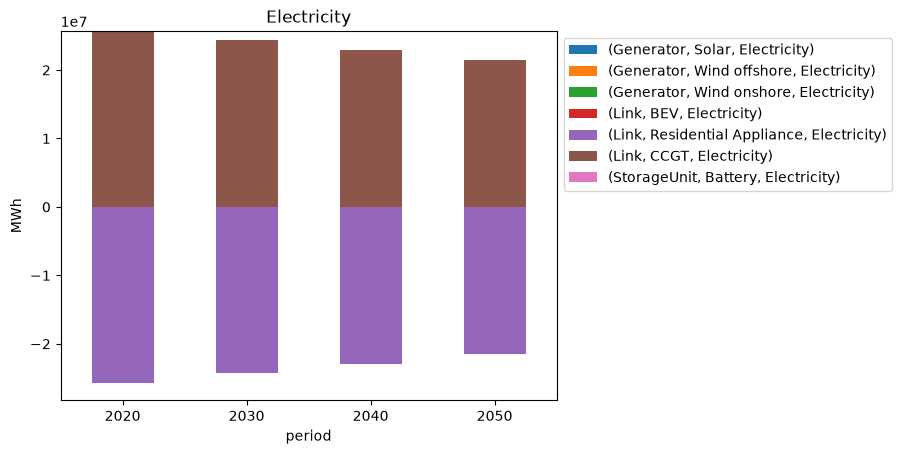

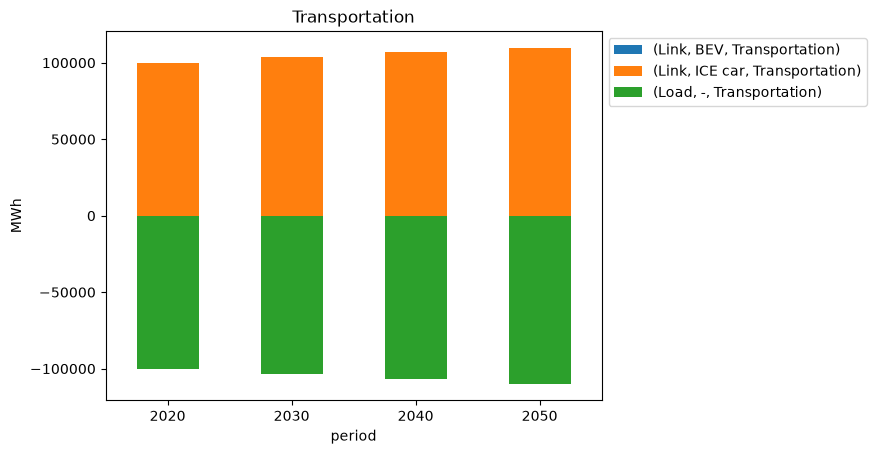

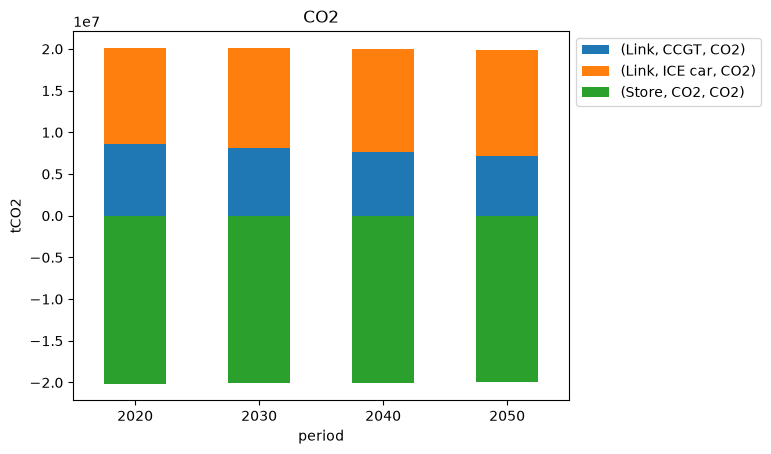

In [ ]:
# Let's have a quick look at some of the energy balances:

for c in ['Electricity','Transportation','CO2']: 
    n.statistics.energy_balance(bus_carrier=c).T.plot(kind='bar',stacked='True', rot=0)
    if c=='CO2':
        plt.ylabel('tCO2')
    else:
        plt.ylabel('MWh')
    plt.legend(bbox_to_anchor=(1,1))
    plt.title(c)